# 04 — Population stability and PD modelling

## Purpose
This notebook compares a logistic-regression baseline with a LightGBM challenger on the 2014 validation period, fits an isotonic probability mapping on 2014, and evaluates the resulting model once on the 2015 out-of-time test period. It also reports how the observed charge-off rate and two borrower and pricing variables changed between periods.

## Inputs and outputs
* Reads the processed PD cohort, `src/features/credit_features.py`, and the training-fitted baseline preprocessor from Notebook 03.
* Saves the unweighted LightGBM model and its isotonic-calibrated version to `models/checkpoints/`. These files are used by Notebooks 05 and 06.

## Scope
Evaluation covers discrimination (ROC-AUC), probability accuracy (Brier score and log loss) and reliability diagrams. Fuller diagnostics are in `04b-Model-Diagnostics-and-Drift.ipynb`: the logistic regression on 2015, Gini and KS, bootstrap intervals, calibration slope and intercept, comparison with simpler recalibrations, PSI for every model input, and a decomposition of drift into mix and within-segment effects. Sensitivity to feature-policy choices is in `04c-Sensitivity-Feature-Policies.ipynb`.

## Future Caution when re-running
The cells that save models overwrite the files that Notebooks 05 and 06 depend on, including the frozen decision threshold. LightGBM results can differ slightly between runs. Re-run the training and saving cells only if you intend to regenerate Notebooks 05 and 06 as well.

importing the required libraries and setup

In [5]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

import sys
project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.features.credit_features import (
    BASELINE_FEATURES,
    split_by_issue_month,
    make_row_features
)

print("Imports successful.")

Imports successful.


load data and preprocessor

In [6]:
pd_file = project_root / "data" / "processed" / "pd_cohort_2011_2015_36m.parquet"
data = pd.read_parquet(pd_file)

# Apply chronological splits and row-level features
splits = split_by_issue_month(data)
train_ready = make_row_features(splits["train"])
validation_ready = make_row_features(splits["validation"])
test_ready = make_row_features(splits["test"])

# Load the saved baseline preprocessor
preprocessor_path = project_root / "models" / "checkpoints" / "baseline_preprocessor_2011_2013.joblib"
baseline_preprocessor = joblib.load(preprocessor_path)

print(f"Train size: {train_ready.shape}")
print(f"Validation size: {validation_ready.shape}")
print(f"Test size: {test_ready.shape}")

Train size: (157993, 36)
Validation size: (162570, 36)
Test size: (283026, 36)


Verify Notebook 03 inputs

In [7]:
# Check that the saved preprocessor expects the feature list used here.
assert list(baseline_preprocessor.feature_names_in_) == list(BASELINE_FEATURES), (
    "Feature names or order differ from the saved Notebook 03 preprocessor."
)

for name, frame in [
    ("train", train_ready),
    ("validation", validation_ready),
    ("test", test_ready),
]:
    assert len(frame) == len(splits[name]), f"{name}: row count changed"
    assert set(BASELINE_FEATURES).issubset(frame.columns), (
        f"{name}: required model features are missing"
    )
    assert frame["id"].is_unique, f"{name}: duplicate loan IDs"
    assert set(frame["charged_off"].unique()).issubset({0, 1}), (
        f"{name}: unexpected target value"
    )
    print(
        f"{name}: {len(frame):,} loans, "
        f"{int(frame['charged_off'].sum()):,} charged off"
    )

assert len(train_ready) + len(validation_ready) + len(test_ready) == len(data)
print("Notebook 03 inputs and saved preprocessor are compatible.")

train: 157,993 loans, 19,780 charged off
validation: 162,570 loans, 22,315 charged off
test: 283,026 loans, 42,132 charged off
Notebook 03 inputs and saved preprocessor are compatible.


### Interpretation of predicted risk

Throughout this notebook, “PD” is used as convenient credit-risk shorthand for the model's predicted probability of the dataset label `charged_off`. That label distinguishes a recorded final status of `Charged Off` from `Fully Paid` among the selected originated 36-month loans. It is **not** default within a fixed number of months after origination. The model uses historical recorded fields, including `verification_status`, whose availability at the intended approval decision point has not been independently verified. Out-of-time evaluation on 2015 loans assesses historical generalisation within this selected dataset; it does not establish production readiness.

population stability index (PSI) function

In [8]:
def calculate_psi(reference, comparison, buckets=10, epsilon=1e-6):
    """PSI using reference-period quantile bins plus a missing-value bin."""
    reference = pd.to_numeric(pd.Series(reference), errors="coerce")
    comparison = pd.to_numeric(pd.Series(comparison), errors="coerce")

    reference_valid = reference.dropna().to_numpy()
    comparison_valid = comparison.dropna().to_numpy()

    if len(reference_valid) == 0 or len(comparison_valid) == 0:
        raise ValueError("Both periods need non-missing observations.")

    edges = np.unique(
        np.quantile(reference_valid, np.linspace(0, 1, buckets + 1))
    )

    if len(edges) < 2:
        raise ValueError(
            "The reference variable is constant; use categorical PSI."
        )

    # Include observations below/above the reference-period range.
    edges[0] = -np.inf
    edges[-1] = np.inf

    reference_counts = np.histogram(reference_valid, bins=edges)[0]
    comparison_counts = np.histogram(comparison_valid, bins=edges)[0]

    # Keep missingness visible as its own bin.
    reference_counts = np.append(reference_counts, reference.isna().sum())
    comparison_counts = np.append(comparison_counts, comparison.isna().sum())

    reference_share = reference_counts / len(reference)
    comparison_share = comparison_counts / len(comparison)

    # Apply smoothing to both distributions, then renormalize.
    reference_share = reference_share + epsilon
    comparison_share = comparison_share + epsilon
    reference_share /= reference_share.sum()
    comparison_share /= comparison_share.sum()

    contributions = (comparison_share - reference_share) * np.log(
        comparison_share / reference_share
    )

    return float(contributions.sum())


psi_dti = calculate_psi(train_ready["dti"], test_ready["dti"])
print(f"DTI PSI, train 2011–2013 vs test 2015: {psi_dti:.4f}")
print(
    "DTI missing: "
    f"train={train_ready['dti'].isna().sum():,}, "
    f"test={test_ready['dti'].isna().sum():,}"
)

DTI PSI, train 2011–2013 vs test 2015: 0.0638
DTI missing: train=0, test=3


Drift Analysis for Credit Mix and Target, plus Data Transformation

In [9]:
# 1. Interest rate is a lender-pricing variable, not a demographic measure.
psi_int_rate = calculate_psi(
    train_ready["int_rate"],
    test_ready["int_rate"]
)

print(
    "Interest-rate PSI, train 2011–2013 vs test 2015: "
    f"{psi_int_rate:.4f}"
)
print(
    "Interpretation: a change in the distribution of observed "
    "loan interest rates; this alone does not establish its cause."
)
    
# 2. Change in observed final-status charge-off rate
train_dr = train_ready['charged_off'].mean() * 100
val_dr = validation_ready['charged_off'].mean() * 100
test_dr = test_ready['charged_off'].mean() * 100

print(f"\nObserved Charge-off Rates (Target Drift):")
print(f"Train (2011-2013): {train_dr:.2f}%")
print(f"Validation (2014): {val_dr:.2f}%")
print(f"Test (2015):       {test_dr:.2f}%")

# 3. Transform the features using the loaded baseline preprocessor
# I do not use fit_transform here, just transform, because the scaler/imputer 
# was already fitted on the training data in Notebook 03!
X_train = baseline_preprocessor.transform(train_ready[BASELINE_FEATURES])
X_val = baseline_preprocessor.transform(validation_ready[BASELINE_FEATURES])
X_test = baseline_preprocessor.transform(test_ready[BASELINE_FEATURES])

y_train = train_ready['charged_off']
y_val = validation_ready['charged_off']
y_test = test_ready['charged_off']

print(f"\nData transformation complete.")
print(f"Transformed X_train shape: {X_train.shape}")
print(f"Transformed X_val shape: {X_val.shape}")
print(f"Transformed X_test shape: {X_test.shape}")

Interest-rate PSI, train 2011–2013 vs test 2015: 0.2945
Interpretation: a change in the distribution of observed loan interest rates; this alone does not establish its cause.

Observed Charge-off Rates (Target Drift):
Train (2011-2013): 12.52%
Validation (2014): 13.73%
Test (2015):       14.89%

Data transformation complete.
Transformed X_train shape: (157993, 98)
Transformed X_val shape: (162570, 98)
Transformed X_test shape: (283026, 98)


### Reading the stability results

* **DTI:** PSI 0.0638, below the conventional 0.10 level, so no material shift between the 2011–2013 training period and 2015.
* **Interest rate:** PSI 0.2945, above the conventional 0.25 level for a major shift. Interest rate is **not** an input to the baseline model (it is a Lending Club pricing output), so this shift does not by itself describe the model's input population. It does show that the lender's pricing, and so presumably its view of risk, moved substantially over the period.
* **Observed charge-off rate:** 12.52% in training, 13.73% in 2014 and 14.89% in 2015.

PSI measures a change in distribution. It does not identify the cause, and the thresholds are conventions, not statistical tests. PSI for all model inputs and for the predicted score is reported in Notebook 04b.

In [12]:
from scipy.sparse import issparse

transformed_feature_names = baseline_preprocessor.get_feature_names_out()

def with_feature_names(matrix, index):
    if matrix.shape[1] != len(transformed_feature_names):
        raise ValueError("Transformed column count does not match feature names.")

    if issparse(matrix):
        return pd.DataFrame.sparse.from_spmatrix(
            matrix,
            index=index,
            columns=transformed_feature_names,
        )

    return pd.DataFrame(
        matrix,
        index=index,
        columns=transformed_feature_names,
    )

X_train_named = with_feature_names(X_train, train_ready.index)
X_val_named = with_feature_names(X_val, validation_ready.index)
X_test_named = with_feature_names(X_test, test_ready.index)

print("Named transformed features:", X_train_named.shape[1])

Named transformed features: 98


Model Training and Checkpointing

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss
import lightgbm as lgb

model_candidates = {
    "Logistic regression — unweighted": LogisticRegression(
        max_iter=1000,
        random_state=42,
    ),
    "Logistic regression — balanced": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    ),
    "LightGBM — unweighted": lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
    "LightGBM — balanced": lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
}

candidate_results = []

for name, model in model_candidates.items():
    model.fit(X_train_named, y_train)
    probabilities = model.predict_proba(X_val_named)[:, 1]

    candidate_results.append({
        "model": name,
        "validation_auc": roc_auc_score(y_val, probabilities),
        "validation_brier": brier_score_loss(y_val, probabilities),
        "validation_log_loss": log_loss(y_val, probabilities),
        "mean_predicted_risk": probabilities.mean(),
        "observed_charge_off_rate": y_val.mean(),
    })

candidate_results = pd.DataFrame(candidate_results).sort_values(
    ["validation_brier", "validation_auc"],
    ascending=[True, False],
)

print(candidate_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"));

                           model  validation_auc  validation_brier  validation_log_loss  mean_predicted_risk  observed_charge_off_rate
           LightGBM — unweighted          0.6600            0.1140               0.3808               0.1305                    0.1373
Logistic regression — unweighted          0.6551            0.1144               0.3824               0.1326                    0.1373
             LightGBM — balanced          0.6598            0.2309               0.6506               0.4696                    0.1373
  Logistic regression — balanced          0.6552            0.2418               0.6759               0.4846                    0.1373


Probability Calibration and Brier Scores

2014 validation — raw, uncalibrated probabilities
Logistic regression: AUC=0.6551, Brier=0.1144, mean predicted=0.1326
LightGBM: AUC=0.6600, Brier=0.1140, mean predicted=0.1305
Observed charge-off rate: 0.1373


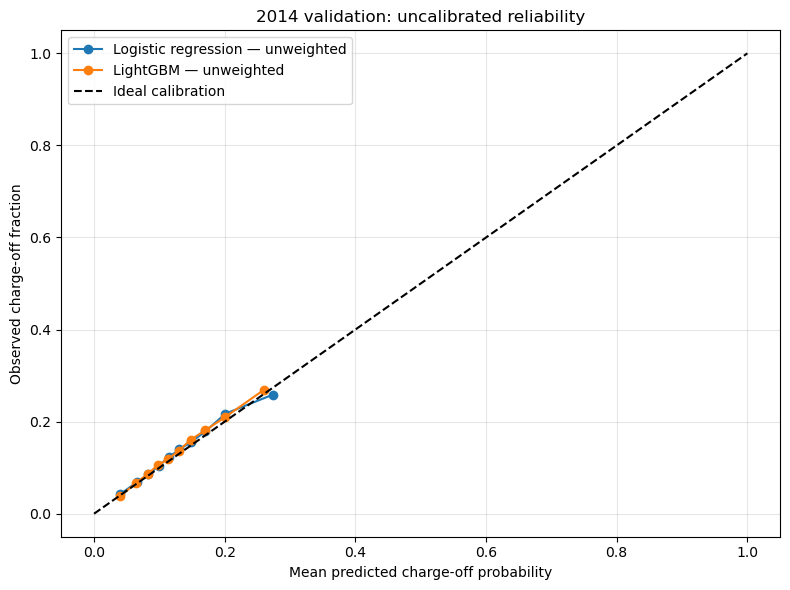

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

# Retrieve the fitted candidates from the comparison cell.
unweighted_lr = model_candidates["Logistic regression — unweighted"]
unweighted_lgb = model_candidates["LightGBM — unweighted"]

val_prob_lr = unweighted_lr.predict_proba(X_val_named)[:, 1]
val_prob_lgb = unweighted_lgb.predict_proba(X_val_named)[:, 1]

print("2014 validation — raw, uncalibrated probabilities")
for name, probability in [
    ("Logistic regression", val_prob_lr),
    ("LightGBM", val_prob_lgb),
]:
    print(
        f"{name}: "
        f"AUC={roc_auc_score(y_val, probability):.4f}, "
        f"Brier={brier_score_loss(y_val, probability):.4f}, "
        f"mean predicted={probability.mean():.4f}"
    )

print(f"Observed charge-off rate: {y_val.mean():.4f}")

fig, ax = plt.subplots(figsize=(8, 6))

for name, probability in [
    ("Logistic regression — unweighted", val_prob_lr),
    ("LightGBM — unweighted", val_prob_lgb),
]:
    observed, predicted = calibration_curve(
        y_val,
        probability,
        n_bins=10,
        strategy="quantile",
    )
    ax.plot(predicted, observed, marker="o", label=name)

ax.plot([0, 1], [0, 1], "k--", label="Ideal calibration")
ax.set_xlabel("Mean predicted charge-off probability")
ax.set_ylabel("Observed charge-off fraction")
ax.set_title("2014 validation: uncalibrated reliability")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "validation_reliability_unweighted_2014.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [15]:
from sklearn.calibration import calibration_curve

def calibration_table(y_true, probabilities, n_bins=10):
    observed, predicted = calibration_curve(
        y_true,
        probabilities,
        n_bins=n_bins,
        strategy="quantile",
    )

    table = pd.DataFrame({
        "mean_predicted_probability": predicted,
        "observed_charge_off_rate": observed,
    })

    table["absolute_gap"] = (
        table["observed_charge_off_rate"]
        - table["mean_predicted_probability"]
    ).abs()

    return table

calibration_lr = calibration_table(y_val, val_prob_lr)
calibration_lgb = calibration_table(y_val, val_prob_lgb)

print("Logistic regression calibration table:")
display(calibration_lr.round(4))

print("LightGBM calibration table:")
display(calibration_lgb.round(4))

Logistic regression calibration table:


,mean_predicted_probability,observed_charge_off_rate,absolute_gap
0,0.0400,0.0423,0.0023
1,0.0658,0.0690,0.0031
2,0.0833,0.0852,0.0019
3,0.0989,0.1041,0.0052
4,0.1142,0.1226,0.0084
5,0.1303,0.1395,0.0092
6,0.1482,0.1554,0.0071
7,0.1702,0.1786,0.0084
8,0.2011,0.2173,0.0162
9,0.2737,0.2587,0.0150


LightGBM calibration table:


,mean_predicted_probability,observed_charge_off_rate,absolute_gap
0,0.0402,0.0380,0.0022
1,0.0648,0.0674,0.0026
2,0.0820,0.0862,0.0042
3,0.0976,0.1057,0.0082
4,0.1130,0.1182,0.0052
5,0.1295,0.1367,0.0072
6,0.1482,0.1610,0.0128
7,0.1705,0.1815,0.0110
8,0.1997,0.2090,0.0093
9,0.2598,0.2689,0.0091


In [16]:
def calibration_summary(calibration_table):
    return {
        "mean_absolute_gap": calibration_table["absolute_gap"].mean(),
        "maximum_absolute_gap": calibration_table["absolute_gap"].max(),
    }

summary = pd.DataFrame({
    "model": [
        "Logistic regression — unweighted",
        "LightGBM — unweighted",
    ],
    "mean_absolute_gap": [
        calibration_summary(calibration_lr)["mean_absolute_gap"],
        calibration_summary(calibration_lgb)["mean_absolute_gap"],
    ],
    "maximum_absolute_gap": [
        calibration_summary(calibration_lr)["maximum_absolute_gap"],
        calibration_summary(calibration_lgb)["maximum_absolute_gap"],
    ],
})

print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                           model  mean_absolute_gap  maximum_absolute_gap
Logistic regression — unweighted             0.0077                0.0162
           LightGBM — unweighted             0.0072                0.0128


### Validation findings before recalibration

On the 2014 validation cohort, both unweighted models produced probabilities broadly aligned with observed final-status charge-off frequencies across ten quantile bins. LightGBM achieved slightly higher discrimination than Logistic Regression (ROC-AUC 0.6600 versus 0.6551) and a slightly lower Brier score (0.1140 versus 0.1144). Their mean predicted charge-off probabilities were 13.05% and 13.26%, respectively, compared with an observed rate of 13.73%.

The mean absolute difference between predicted and observed rates across the ten displayed bins was 0.72 percentage points for LightGBM and 0.77 percentage points for Logistic Regression. The maximum gaps were 1.28 and 1.62 percentage points, respectively. These are descriptive, unweighted averages of bin-level gaps—not individual-level calibration errors or substitutes for the Brier score.

The validation results suggest that the raw unweighted probabilities were already reasonably aligned with observed rates, with some aggregate underprediction. Isotonic calibration was evaluated as a pre-specified additional adjustment, not assumed to be necessary or guaranteed to improve out-of-time results.

Recalibration and Out-of-Time (OOT) Test Evaluation (2015)

scikit-learn version: 1.6.1
2015 observed charge-off rate: 0.1489
                          model    auc  brier  log_loss  mean_predicted_risk
     LightGBM — unweighted, raw 0.6625 0.1219    0.4011               0.1287
LightGBM — unweighted, isotonic 0.6624 0.1216    0.4001               0.1352


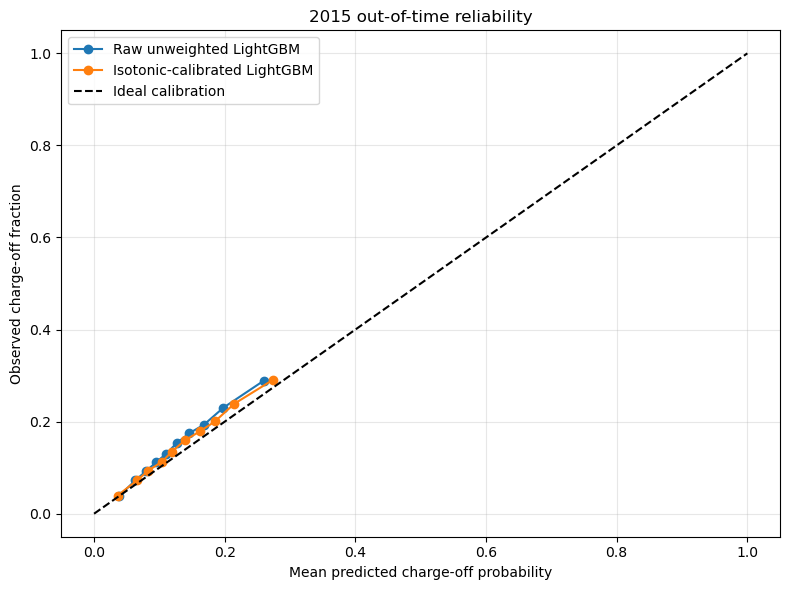

In [ ]:
from sklearn import __version__ as sklearn_version
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

print("scikit-learn version:", sklearn_version)

# The base model was fitted on 2011–2013.
# Fit only the isotonic mapping on the separate 2014 validation cohort.
calibrated_lgb = CalibratedClassifierCV(
    estimator=FrozenEstimator(unweighted_lgb),
    method="isotonic",
)
calibrated_lgb.fit(X_val_named, y_val)

# Assess both versions on the 2015 OOT cohort.
oot_raw = unweighted_lgb.predict_proba(X_test_named)[:, 1]
oot_calibrated = calibrated_lgb.predict_proba(X_test_named)[:, 1]

oot_results = pd.DataFrame([
    {
        "model": "LightGBM — unweighted, raw",
        "auc": roc_auc_score(y_test, oot_raw),
        "brier": brier_score_loss(y_test, oot_raw),
        "log_loss": log_loss(y_test, oot_raw),
        "mean_predicted_risk": oot_raw.mean(),
    },
    {
        "model": "LightGBM — unweighted, isotonic",
        "auc": roc_auc_score(y_test, oot_calibrated),
        "brier": brier_score_loss(y_test, oot_calibrated),
        "log_loss": log_loss(y_test, oot_calibrated),
        "mean_predicted_risk": oot_calibrated.mean(),
    },
])

print("2015 observed charge-off rate:", round(y_test.mean(), 4))
print(oot_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(8, 6))

for label, probabilities in [
    ("Raw unweighted LightGBM", oot_raw),
    ("Isotonic-calibrated LightGBM", oot_calibrated),
]:
    observed, predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile",
    )
    ax.plot(predicted, observed, marker="o", label=label)

ax.plot([0, 1], [0, 1], "k--", label="Ideal calibration")
ax.set_xlabel("Mean predicted charge-off probability")
ax.set_ylabel("Observed charge-off fraction")
ax.set_title("2015 out-of-time reliability")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "oot_reliability_unweighted_isotonic_2015.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

Save the calibrated model

In [18]:
calibrated_model_path = (
    project_root
    / "models"
    / "checkpoints"
    / "calibrated_lightgbm_unweighted_isotonic.joblib"
)

joblib.dump(calibrated_lgb, calibrated_model_path)

print(f"Saved calibrated model: {calibrated_model_path.name}")

Saved calibrated model: calibrated_lightgbm_unweighted_isotonic.joblib


save the raw unweighted LightGBM model used by the calibrated object

In [19]:
raw_model_path = (
    project_root
    / "models"
    / "checkpoints"
    / "lightgbm_challenger_unweighted.joblib"
)

joblib.dump(unweighted_lgb, raw_model_path)

print(f"Saved raw model: {raw_model_path.name}")

Saved raw model: lightgbm_challenger_unweighted.joblib


## Calibration and out-of-time evaluation

The unweighted LightGBM model was taken forward as the challenger based on its modest validation advantage. Its underlying model was fitted on 2011–2013 loans, and an isotonic calibration mapping was fitted on the separate 2014 validation cohort. The 2015 cohort was used to evaluate the resulting frozen model, not to fit the mapping.

On the 2015 out-of-time cohort, the raw and isotonic-calibrated LightGBM models achieved ROC-AUC values of 0.6625 and 0.6624. The Brier score moved from 0.1219 to 0.1216 and log loss from 0.4011 to 0.4001. These changes are very small, and this notebook does not test whether they are distinguishable from sampling noise; Notebook 04b does, and compares isotonic calibration with simpler recalibrations fitted on the same 2014 data. Mean predicted charge-off probability rose from 12.87% to 13.52%, compared with an observed rate of 14.89%, so both versions under-predict in 2015. The reliability diagram does not establish perfect calibration or the accuracy of any individual loan's probability. These probabilities estimate the observed final-status charge-off outcome in this selected historical cohort, not default within a fixed time horizon.

## Limitations and next step

* **Model comparison on the test period.** The logistic-regression baseline was compared with LightGBM on 2014 validation only. Its 2015 results, with confidence intervals, are in Notebook 04b.
* **No hyperparameter tuning.** The LightGBM settings are fixed (200 trees, learning rate 0.05). The AUC of about 0.66 is modest, and a tuned model might do better. Tuning would have to use the 2014 validation data only.
* **Calibration.** Aggregate under-prediction persists in 2015 after isotonic calibration. A calibration fitted on 2014 cannot adapt to a level shift that continues to grow; this is examined in Notebook 04b.
* **Drift analysis.** PSI here covers DTI and interest rate only. Notebook 04b covers every model input and the predicted score. Neither establishes that macroeconomic conditions caused the drift.
* **Feature policy and label availability.** The baseline includes `verification_status`, `home_ownership` and `addr_state`, and uses final outcomes for 2014 loans as a calibration set. See the limitations in Notebooks 01 and 03, and the sensitivity analysis in Notebook 04c.
* **Target.** The label is a recorded final Charged Off status among resolved 36-month loans, not default within a fixed horizon.

**Next:** `04b-Model-Diagnostics-and-Drift.ipynb`, then `04c-Sensitivity-Feature-Policies.ipynb`, then Notebook 05, which uses the saved calibrated model.